# 01b. The mission, reverse-engineered

What was the boat actually told to do? Here we guess the plan an operator would have given Scout, using the simplest possible description. Three parts:

1. **Starlink schedule:** when the terminal wakes and for how long (the predictable part only)
2. **Modes:** which autopilot mode the boat was in, with the short operator blips removed
3. **Waypoints and speed:** a list of legs, each with a target point and the speed the boat sailed it at

Then maps of the modes and of the waypoints.

This is a guess built from telemetry, not the real mission file. The boat only reports the *active* waypoint (and only over Starlink), so we see one waypoint at a time, never the whole list. There are richer ways to model a mission (full waypoint lists, speed set by energy, loiter radius, and so on). This notebook keeps to the basics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (14, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load, both links
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, Starlink rows only

# Starlink sessions: same rule as nb 03 (Starlink messages < 2 min apart = one session)
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
sessions["minutes"] = (sessions.end - sessions.start).dt.total_seconds() / 60

MODE_NAMES = {0: "MANUAL", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
STARLINK_W = 22                                                  # nb 03
print(f"{len(sessions)} Starlink sessions, {sessions.start.min():%d %b %H:%M} to {sessions.end.max():%d %b %H:%M}")

def dist_m(lat1, lon1, lat2, lon2):
    """Great-circle distance in metres."""
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(np.asarray(lon2) - np.asarray(lon1)) / 2) ** 2
    return 2 * 6_371_000 * np.arcsin(np.sqrt(a))

MODE_COLORS = {0: "#7f7f7f", 10: "#1f77b4", 17: "#d62728"}

159 Starlink sessions, 14 Jul 07:43 to 27 Jul 02:05


# 1. Starlink schedule

*(Moved here from nb 06.)*

Each Starlink session is a bar at its time of day, one row per day. Starlink always comes up at about **:47 past the hour**, so a session that starts between **:44 and :56** counts as **scheduled** (dark blue). Anything else is **extra** (light blue), most likely switched on by hand from shore.

The schedule has three phases (read off the plot, then checked in the table below):
- **Deployment, 14 Jul 07:43 to 15 Jul 20:00:** on for hours at a time, no schedule.
- **Every 2 h, 15 Jul 20:00 to 19 Jul 22:00:** at even UTC hours (00:47, 02:47, …).
- **Every 3 h, 19 Jul 22:00 to 27 Jul 02:05:** at 01:47, 04:47, 07:47, …, 22:47.

After 27 Jul 02:05 Starlink never comes back (last day, see nb 02). The small grey ticks mark each phase's scheduled slots, so a tick with no bar on it is a **missed slot**. Neither schedule includes 03:00, which is why there's never a Starlink row in that hour (nb 01).

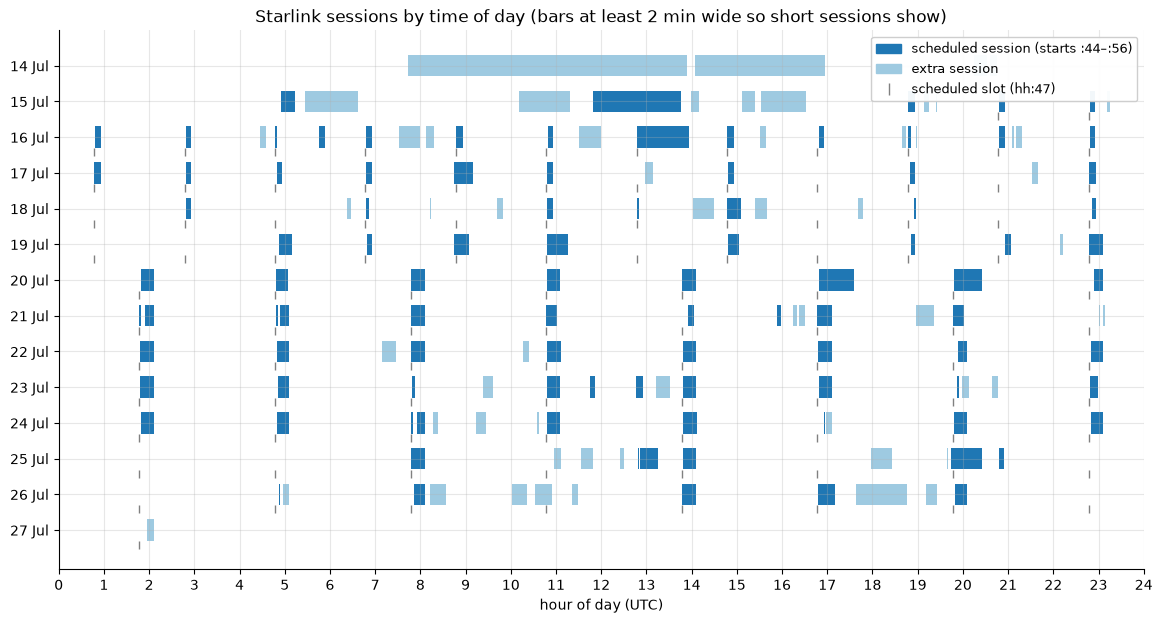

,sessions,scheduled,slots hit,median scheduled length (min),Starlink on (h per day),average Starlink power (W)
phase,,,,,,
deployment,14,3,NaN,18.1,10.5,9.6
every 2 h,57,38,37 / 49,7.7,2.4,2.2
every 3 h,88,58,48 / 58,16.3,2.9,2.6


In [2]:
PHASES = [   # name, start, end, scheduled UTC hours (None = no schedule)
    ("deployment", "2025-07-14 00:00", "2025-07-15 20:00", None),
    ("every 2 h",  "2025-07-15 20:00", "2025-07-19 22:00", list(range(0, 24, 2))),
    ("every 3 h",  "2025-07-19 22:00", "2025-07-27 02:30", [1, 4, 7, 10, 13, 16, 19, 22]),
    ("off",        "2025-07-27 02:30", "2025-07-31 00:00", None),
]
PHASES = [(n, pd.Timestamp(a, tz="UTC"), pd.Timestamp(b, tz="UTC"), h) for n, a, b, h in PHASES]
sessions["scheduled"] = sessions.start.dt.minute.between(44, 56)
sessions["phase"] = [next(n for n, a, b, _ in PHASES if a <= t < b) for t in sessions.start]

# scheduled slots (slot at hh:47) and whether a session started within :44-:56 of it
slots = pd.DataFrame([(n, s + pd.Timedelta("47min")) for n, a, b, hrs in PHASES if hrs
                      for s in pd.date_range(a, b, freq="1h", inclusive="left") if s.hour in hrs], columns=["phase", "t"])
slots["hit"] = [((sessions.start >= t - pd.Timedelta("3min")) & (sessions.start <= t + pd.Timedelta("9min"))).any() for t in slots.t]

days = pd.date_range("2025-07-14", "2025-07-27", tz="UTC")
fig, ax = plt.subplots(figsize=(14, 7))
for i, day in enumerate(days):
    for s in sessions[sessions.start.dt.floor("D") == day].itertuples():
        h0 = (s.start - day).total_seconds() / 3600
        ax.barh(i, max(s.minutes, 2) / 60, left=h0, height=0.6, color="#1f77b4" if s.scheduled else "#9ecae1", lw=0)
    sl = slots[slots.t.dt.floor("D") == day]
    ax.plot((sl.t - day).dt.total_seconds() / 3600, np.full(len(sl), i + 0.42), "|", ms=6, color="grey")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [Patch(color="#1f77b4", label="scheduled session (starts :44–:56)"), Patch(color="#9ecae1", label="extra session"),
           Line2D([], [], marker="|", ls="", ms=8, color="grey", label="scheduled slot (hh:47)")]
ax.set_yticks(range(len(days)), [f"{d:%d %b}" for d in days]); ax.invert_yaxis()
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 1))
ax.set_xlabel("hour of day (UTC)")
ax.set_title("Starlink sessions by time of day (bars at least 2 min wide so short sessions show)")
ax.legend(handles=handles, loc="upper right", fontsize=9, framealpha=0.95)
plt.show()

g = sessions.groupby("phase", sort=False)
span_h = {n: (min(b, sessions.end.max()) - max(a, sessions.start.min())).total_seconds() / 3600 for n, a, b, _ in PHASES if n != "off"}
table = pd.DataFrame({
    "sessions": g.size(),
    "scheduled": g.scheduled.sum(),
    "slots hit": slots.groupby("phase").hit.sum().astype(int).astype(str) + " / " + slots.groupby("phase").size().astype(str),
    "median scheduled length (min)": g.apply(lambda x: x[x.scheduled].minutes.median()),
    "Starlink on (h per day)": g.minutes.sum() / 60 / pd.Series(span_h) * 24,
})
table["average Starlink power (W)"] = table["Starlink on (h per day)"] / 24 * STARLINK_W
table.round(1)

### The predictable part, as the boat would have been given it

Drop the extra (hand-switched) sessions and the deployment day, and the schedule is just a table: from when, at which hours, for how long. Starlink wakes at **hh:47** and stays up for the median scheduled length of that phase.

In [3]:
STARLINK_SCHEDULE = []
for name, a, b, hrs in PHASES:
    if hrs is None:
        continue
    STARLINK_SCHEDULE.append({
        "from": a, "to": min(b, sessions.end.max()),
        "wake at (UTC)": ", ".join(f"{h:02d}:47" for h in hrs),
        "on for (min)": round(sessions[(sessions.phase == name) & sessions.scheduled].minutes.median()),
    })
STARLINK_SCHEDULE.append({"from": PHASES[-1][1], "to": pd.Timestamp("2025-07-31", tz="UTC"),
                          "wake at (UTC)": "never (off)", "on for (min)": 0})
STARLINK_SCHEDULE = pd.DataFrame(STARLINK_SCHEDULE)
STARLINK_SCHEDULE.style.format({"from": "{:%d %b %H:%M}", "to": "{:%d %b %H:%M}"})

,from,to,wake at (UTC),on for (min)
0,15 Jul 20:00,19 Jul 22:00,"00:47, 02:47, 04:47, 06:47, 08:47, 10:47, 12:47, 14:47, 16:47, 18:47, 20:47, 22:47",8
1,19 Jul 22:00,27 Jul 02:05,"01:47, 04:47, 07:47, 10:47, 13:47, 16:47, 19:47, 22:47",16
2,27 Jul 02:30,31 Jul 00:00,never (off),0


# 2. Modes

The boat logs a mode on every message (both links). The raw sequence has 86 mode runs, but many last seconds: an operator flicking to MANUAL and back, or a reboot (INITIALISING). **Any run shorter than 10 min is absorbed into the mode before it.** What's left is the mode plan.

- **AUTO (10):** sail to the active waypoint, then hold near it
- **mode 17:** not a stock Rover mode. It sets the waypoint to where the boat is when it starts and then sails a steady heading away from it, at ~0.8–1.1 m/s (nb 03: power-capped)
- **MANUAL (0):** motor off, the boat drifts

82 raw mode runs -> 27 after removing blips < 10 min


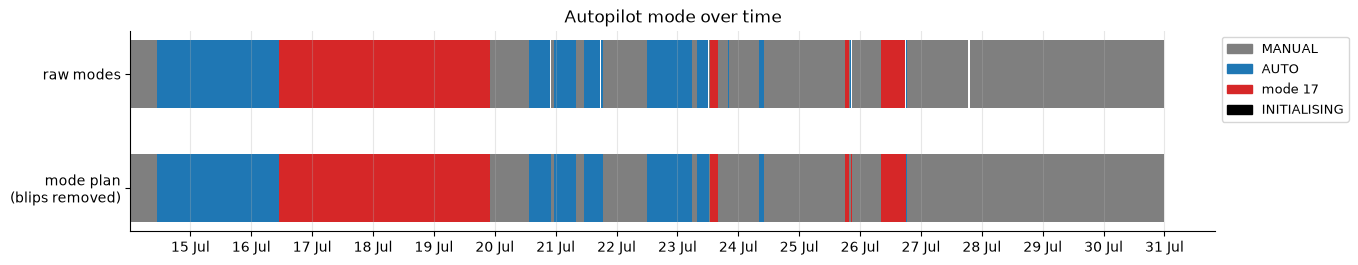

,start,end,hours,name
0,14 Jul 00:20,14 Jul 10:52,10.5,MANUAL
1,14 Jul 10:52,16 Jul 11:03,48.2,AUTO
2,16 Jul 11:03,19 Jul 22:10,83.1,mode 17
3,19 Jul 22:10,20 Jul 13:29,15.3,MANUAL
4,20 Jul 13:29,20 Jul 22:00,8.5,AUTO
5,20 Jul 22:00,20 Jul 23:29,1.5,MANUAL
6,20 Jul 23:29,21 Jul 07:55,8.4,AUTO
7,21 Jul 07:55,21 Jul 11:00,3.1,MANUAL
8,21 Jul 11:00,21 Jul 17:42,6.7,AUTO
9,21 Jul 17:42,21 Jul 18:01,0.3,MANUAL


In [4]:
m = df[df.custom_mode.notna() & (df.latitude_deg != 0)].copy()        # both links; drop the (0, 0) reboot rows
m["run"] = (m.custom_mode != m.custom_mode.shift()).cumsum()
run_min = m.groupby("run").t.agg(lambda x: (x.max() - x.min()).total_seconds() / 60)
keep = m.run.map(run_min).ge(10) & m.custom_mode.isin([0, 10, 17])
m["mode"] = m.custom_mode.where(keep).ffill().bfill().astype(int)

modes = (m.assign(r=(m["mode"] != m["mode"].shift()).cumsum())
          .groupby("r").agg(start=("t", "min"), mode=("mode", "first")).reset_index(drop=True))
modes["end"] = modes.start.shift(-1).fillna(m.t.max())
modes["hours"] = (modes.end - modes.start).dt.total_seconds() / 3600
modes["name"] = modes["mode"].map(MODE_NAMES)
print(f"{run_min.size} raw mode runs -> {len(modes)} after removing blips < 10 min")

fig, ax = plt.subplots(figsize=(14, 2.6))
raw = m.assign(r=m.run).groupby("r").agg(start=("t", "min"), end=("t", "max"), mode=("custom_mode", "first"))
for y, tab in [(1, raw), (0, modes)]:
    for s in tab.itertuples():
        ax.barh(y, s.end - s.start, left=s.start, height=0.6, color=MODE_COLORS.get(s.mode, "black"), lw=0)
ax.set_yticks([0, 1], ["mode plan\n(blips removed)", "raw modes"])
ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(handles=[Patch(color=c, label=MODE_NAMES[k]) for k, c in MODE_COLORS.items()] + [Patch(color="black", label="INITIALISING")],
          loc="upper left", bbox_to_anchor=(1, 1), fontsize=9)
ax.set_title("Autopilot mode over time"); ax.grid(axis="y", visible=False)
plt.show()

modes.style.format({"start": "{:%d %b %H:%M}", "end": "{:%d %b %H:%M}", "hours": "{:.1f}"}).hide(axis="columns", subset=["mode"])

# 3. Waypoints at 1 m/s

The simplest mission: **a short list of waypoints, and the boat sails between them at a nominal 1 m/s.** When it isn't sailing it waits (motor off, it drifts).

How the list is made:
1. Label each piece of the mode plan as **sailing** (AUTO on its way to a waypoint, or a mode-17 heading leg), **holding** (AUTO parked near its waypoint, or mode 17 circling) or **drifting** (MANUAL). The rules are in the code below.
2. Join sailing pieces less than 15 min apart into **runs**. Each run starts at some time from wherever the boat is.
3. Simplify each run's track to a few corners (Ramer–Douglas–Peucker, **3 km** tolerance). Those corners are the waypoints. Runs shorter than 2 km are dropped.

So the mission reads: *at time T, sail through waypoints i, j, k at 1 m/s, then wait until the next run.* We don't use the reported waypoint here: the operator often pointed the boat at a far waypoint and stopped it before it got there, so where the boat actually turned is a better guide.

In [5]:
# the operator sets the waypoint when switching mode, but we only see it at the next Starlink report:
# so inside each mode run, back-fill to the start of the run, then carry forward
mode_run = (m["mode"] != m["mode"].shift()).cumsum()
for c, w in [("wp_lat", "wp_latitude_deg"), ("wp_lon", "wp_longitude_deg")]:
    m[c] = m[w].groupby(mode_run).bfill().ffill().bfill()
wp_id, ref, k = [], None, 0                       # new waypoint id when it jumps > 200 m
for la, lo in zip(m.wp_lat, m.wp_lon):
    if ref is None or dist_m(ref[0], ref[1], la, lo) > 200:
        ref, k = (la, lo), k + 1
    wp_id.append(k)
m["wp_id"] = wp_id
m["piece"] = ((m["mode"] != m["mode"].shift()) | ((m.wp_id != m.wp_id.shift()) & (m["mode"] != 0))).cumsum()
m["d_wp"] = dist_m(m.latitude_deg, m.longitude_deg, m.wp_lat, m.wp_lon)

def speed(g):
    """Median of per-minute mean SOG, to 0.1 m/s."""
    return round(g.groupby(g.t.dt.floor("1min")).groundspeed_ms.mean().median(), 1) if len(g) else np.nan

def leg(g, kind, lat, lon, v):
    return {"start": g.t.iloc[0], "end": g.t.iloc[-1], "mode": MODE_NAMES[g["mode"].iloc[0]], "leg": kind,
            "lat": lat, "lon": lon, "speed (m/s)": v,
            "lat0": g.latitude_deg.iloc[0], "lon0": g.longitude_deg.iloc[0],
            "lat1": g.latitude_deg.iloc[-1], "lon1": g.longitude_deg.iloc[-1]}

legs = []
for _, g in m.groupby("piece"):
    mode, wl, wo = g["mode"].iloc[0], g.wp_lat.iloc[-1], g.wp_lon.iloc[-1]
    if mode == 0:
        legs.append(leg(g, "drift", np.nan, np.nan, 0.0))
    elif mode == 10:
        near = g.d_wp.lt(1500).cummax()                         # True from the first time within 1.5 km
        go, hold = g[~near], g[near]
        if len(hold) < 2 or hold.t.iloc[-1] - hold.t.iloc[0] < pd.Timedelta("30min"):
            go, hold = g, g.iloc[:0]                            # short hold: count it all as transit
        if len(go):
            legs.append(leg(go, "transit", wl, wo, speed(go)))
        if len(hold):
            legs.append(leg(hold, "hold", wl, wo, 0.0))
    else:  # mode 17
        hours = (g.t.iloc[-1] - g.t.iloc[0]).total_seconds() / 3600
        net = dist_m(g.latitude_deg.iloc[0], g.longitude_deg.iloc[0], g.latitude_deg.iloc[-1], g.longitude_deg.iloc[-1])
        v = speed(g)
        if net / max(hours * 3600, 1) > 0.5 * v:
            legs.append(leg(g, "heading", g.latitude_deg.iloc[-1], g.longitude_deg.iloc[-1], v))
        else:
            legs.append(leg(g, "hold", g.latitude_deg.mean(), g.longitude_deg.mean(), 0.0))

legs = pd.DataFrame(legs)
legs["hours"] = (legs.end - legs.start).dt.total_seconds() / 3600
legs = legs[legs.hours >= 5 / 60].reset_index(drop=True)
legs.index = legs.index + 1
legs.index.name = "leg"
legs["km"] = dist_m(legs.lat0, legs.lon0, legs.lat1, legs.lon1) / 1000

print(f"{len(legs)} legs:", legs.leg.value_counts().to_dict())

49 legs: {'transit': 19, 'drift': 13, 'heading': 11, 'hold': 6}


In [6]:
def rdp(xy, tol):
    """Ramer-Douglas-Peucker: indices of the points to keep."""
    if len(xy) < 3:
        return list(range(len(xy)))
    a, ab = xy[0], xy[-1] - xy[0]
    L = np.hypot(*ab)
    d = np.abs(ab[0] * (xy[:, 1] - a[1]) - ab[1] * (xy[:, 0] - a[0])) / L if L > 0 else np.hypot(*(xy - a).T)
    i = int(np.argmax(d))
    if d[i] <= tol:
        return [0, len(xy) - 1]
    return rdp(xy[:i + 1], tol)[:-1] + [j + i for j in rdp(xy[i:], tol)]

V_NOMINAL, TOL_M, MIN_RUN_KM = 1.0, 3000, 2.0
sail = legs[legs.leg.isin(["transit", "heading"])].copy()
sail["run"] = (sail.start - sail.end.shift() > pd.Timedelta("15min")).cumsum()
track = m[m.latitude_deg.between(55, 70)]
lat_mid = track.latitude_deg.median()
to_xy = lambda p: np.c_[p.longitude_deg * 111_320 * np.cos(np.radians(lat_mid)), p.latitude_deg * 110_540]

rows = []
for _, r in sail.groupby("run"):
    p = track[track.t.between(r.start.min(), r.end.max())]
    p = p[p.groupby(p.t.dt.floor("2min")).cumcount() == 0]            # one fix per 2 min
    xy = to_xy(p)
    if np.hypot(*np.diff(xy, axis=0).T).sum() < MIN_RUN_KM * 1000:
        continue
    keep = rdp(xy, TOL_M)
    for k in range(1, len(keep)):
        a, b = p.iloc[keep[k - 1]], p.iloc[keep[k]]
        rows.append({"depart": a.t if k == 1 else pd.NaT, "lat": b.latitude_deg, "lon": b.longitude_deg,
                     "from_lat": a.latitude_deg, "from_lon": a.longitude_deg,
                     "km": dist_m(a.latitude_deg, a.longitude_deg, b.latitude_deg, b.longitude_deg) / 1000,
                     "actual (h)": (b.t - a.t).total_seconds() / 3600})
WAYPOINTS = pd.DataFrame(rows)
WAYPOINTS.index = WAYPOINTS.index + 1
WAYPOINTS.index.name = "wp"
WAYPOINTS["at 1 m/s (h)"] = WAYPOINTS.km * 1000 / V_NOMINAL / 3600

tot = WAYPOINTS[["km", "actual (h)", "at 1 m/s (h)"]].sum()
print(f"{len(WAYPOINTS)} waypoints in {WAYPOINTS.depart.notna().sum()} runs, {tot['km']:.0f} km. "
      f"Sailing time: actual {tot['actual (h)']:.0f} h, at 1 m/s {tot['at 1 m/s (h)']:.0f} h")
WAYPOINTS[["depart", "lat", "lon", "km", "at 1 m/s (h)", "actual (h)"]].style.format(
    {"depart": "{:%d %b %H:%M}", "lat": "{:.4f}", "lon": "{:.4f}", "km": "{:.1f}",
     "at 1 m/s (h)": "{:.1f}", "actual (h)": "{:.1f}"}, na_rep="")

18 waypoints in 12 runs, 345 km. Sailing time: actual 114 h, at 1 m/s 96 h


,depart,lat,lon,km,at 1 m/s (h),actual (h)
wp,,,,,,
1,14 Jul 10:52,60.3764,2.0014,7.2,2.0,2.2
2,14 Jul 15:22,60.4000,1.9732,2.2,0.6,0.7
3,15 Jul 05:49,60.4609,1.7663,11.6,3.2,3.3
4,,61.1885,0.8526,94.9,26.4,25.8
5,18 Jul 11:09,61.3227,0.9548,29.5,8.2,15.0
6,,61.3123,0.8765,4.3,1.2,3.7
7,,61.3306,1.1537,14.9,4.1,7.1
8,,61.4384,1.3477,15.8,4.4,5.1
9,,61.5662,1.3675,14.2,4.0,4.1


`depart` is filled on the first waypoint of each run: that's when the boat sets off from wherever it drifted to. The other waypoints follow straight on. Comparing the last two columns tells you how good the 1 m/s assumption is per bit: where actual time is longer, the boat was slower (current against it, or the mode-17 power cap); where it's shorter, faster.

# 4. Maps

Map 3 (below) shows the motor power along the track. Map 1 is the whole track coloured by the mode plan from section 2. Map 2 is the 1 m/s mission: numbered waypoints joined by straight bits, each run starting (dashed) from where the boat was when it set off, over the real track in grey.

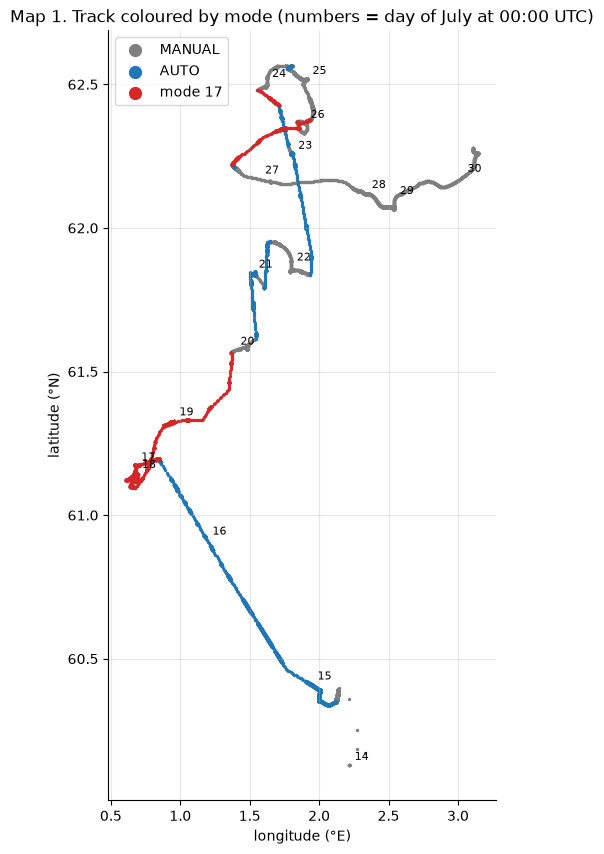

In [7]:
def geo_axes(ax, title):
    ax.set_aspect(1 / np.cos(np.radians(lat_mid)))
    ax.set_xlabel("longitude (°E)"); ax.set_ylabel("latitude (°N)"); ax.set_title(title)

fig, ax = plt.subplots(figsize=(10, 10))
for mode, c in MODE_COLORS.items():
    p = track[track["mode"] == mode]
    ax.scatter(p.longitude_deg, p.latitude_deg, s=2, color=c, label=MODE_NAMES[mode])
for day in pd.date_range("2025-07-14", "2025-07-30", tz="UTC"):
    p = track[track.t >= day].head(1)
    if len(p):
        ax.annotate(f"{day:%d}", (p.longitude_deg.iloc[0], p.latitude_deg.iloc[0]), fontsize=8,
                    xytext=(4, 4), textcoords="offset points", color="black")
ax.legend(markerscale=6, loc="upper left")
geo_axes(ax, "Map 1. Track coloured by mode (numbers = day of July at 00:00 UTC)")
plt.show()

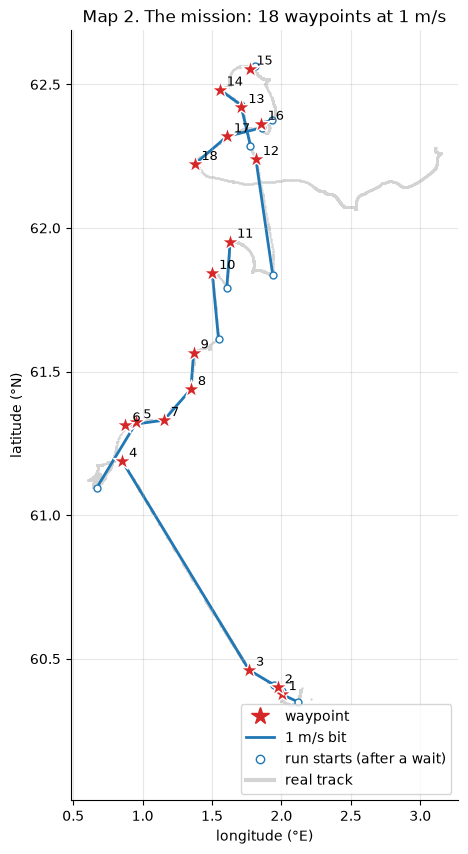

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(track.longitude_deg, track.latitude_deg, s=0.5, color="lightgrey", zorder=0)
W = WAYPOINTS
for i, r in W.iterrows():
    first = pd.notna(r.depart)
    ax.plot([r.from_lon, r.lon], [r.from_lat, r.lat], color="#1f77b4", lw=2, zorder=1)
    if first:
        ax.plot(r.from_lon, r.from_lat, "o", ms=5, color="#1f77b4", mfc="white", zorder=2)
ax.scatter(W.lon, W.lat, marker="*", s=180, color="#d62728", edgecolor="white", zorder=3)
for i, r in W.iterrows():
    ax.annotate(str(i), (r.lon, r.lat), fontsize=9, xytext=(5, 3), textcoords="offset points")
ax.legend(handles=[Line2D([], [], marker="*", ls="", ms=13, color="#d62728", label="waypoint"),
                   Line2D([], [], color="#1f77b4", lw=2, label="1 m/s bit"),
                   Line2D([], [], marker="o", ls="", ms=6, color="#1f77b4", mfc="white", label="run starts (after a wait)"),
                   Line2D([], [], color="lightgrey", lw=3, label="real track")], loc="lower right")
geo_axes(ax, f"Map 2. The mission: {len(W)} waypoints at {V_NOMINAL:.0f} m/s")
plt.show()

### Map 3. Motor power

Motor power = **load − 10 W hotel − 22 W × Starlink** (nb 03), so what's left is roughly the thruster. Load = battery1 V × battery2 A, which both links carry. Starlink counts as on inside a Starlink session (messages < 2 min apart) ± 30 s, the same rule as nb 03. Values are averaged per minute (so the 1 Hz Starlink days don't dominate) and plotted in time order. Negative values (noise around a motor that's off) show as 0, and the colour scale stops at 120 W.

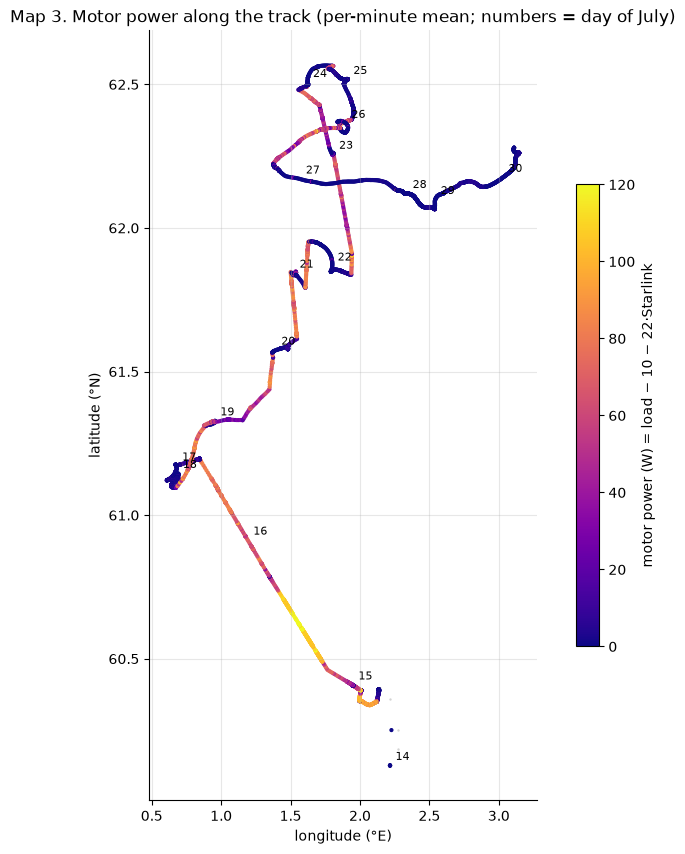

5899 minutes with load; median motor power 4 W, share of minutes above 20 W 34%


In [9]:
HOTEL_W = 10                                                     # nb 03
on_sl = np.zeros(len(df), dtype=bool)
for s in sessions.itertuples():
    on_sl |= df.t.between(s.start - pd.Timedelta("30s"), s.end + pd.Timedelta("30s")).values
mp = df.assign(P_motor=df.P_load - HOTEL_W - STARLINK_W * on_sl)
mp = mp[mp.latitude_deg.between(55, 70)].dropna(subset=["P_motor"])
mp = (mp.set_index("t")[["latitude_deg", "longitude_deg", "P_motor"]]
        .resample("1min").mean().dropna())

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(track.longitude_deg, track.latitude_deg, s=0.5, color="lightgrey", zorder=0)
sc = ax.scatter(mp.longitude_deg, mp.latitude_deg, c=mp.P_motor.clip(lower=0), s=4,
                cmap="plasma", vmin=0, vmax=120, zorder=1)
fig.colorbar(sc, ax=ax, shrink=0.6, label="motor power (W) = load − 10 − 22·Starlink")
for day in pd.date_range("2025-07-14", "2025-07-30", tz="UTC"):
    p = track[track.t >= day].head(1)
    if len(p):
        ax.annotate(f"{day:%d}", (p.longitude_deg.iloc[0], p.latitude_deg.iloc[0]), fontsize=8,
                    xytext=(4, 4), textcoords="offset points")
geo_axes(ax, "Map 3. Motor power along the track (per-minute mean; numbers = day of July)")
plt.show()
print(f"{len(mp)} minutes with load; median motor power {mp.P_motor.median():.0f} W, "
      f"share of minutes above 20 W {(mp.P_motor > 20).mean():.0%}")

# 5. The mission, in one place

What we'd hand a simulator (or the low-power mode) to replay this deployment:

- `STARLINK_SCHEDULE`: wake times and on-length per phase (section 1)
- `modes`: the mode plan (section 2)
- `WAYPOINTS`: when each run departs, and the waypoints it sails through at 1 m/s (section 3)

Both are saved to `data/mission_starlink.csv` and `data/mission_waypoints.csv` for the forecast in nb 06. The Starlink file also gets the deployment phase as a **duty cycle** (share of the time Starlink was on, from the table in section 1), since it had no schedule.

**Known gaps:** the deployment day's Starlink and the extra hand-switched sessions aren't in the schedule; waypoints are corners of the real track, not the waypoints the operator typed; holds and drifts are just "wait"; 1 m/s ignores current and the mode-17 power cap.

In [10]:
dep = table.loc["deployment"]
sl_out = pd.concat([
    pd.DataFrame([{"from": PHASES[0][1], "to": PHASES[0][2], "wake_hours": "", "on_min": 0,
                   "duty": dep["Starlink on (h per day)"] / 24}]),
    STARLINK_SCHEDULE.assign(wake_hours=[" ".join(x.split(":")[0] for x in w.split(", ")) if ":" in w else "" for w in STARLINK_SCHEDULE["wake at (UTC)"]],
                             on_min=STARLINK_SCHEDULE["on for (min)"], duty=0.0)[["from", "to", "wake_hours", "on_min", "duty"]],
], ignore_index=True)
sl_out.to_csv("../data/mission_starlink.csv", index=False)
WAYPOINTS[["depart", "lat", "lon", "from_lat", "from_lon", "km"]].to_csv("../data/mission_waypoints.csv")
print(sl_out.to_string()); print(f"{len(WAYPOINTS)} waypoints saved")

                       from                               to                           wake_hours  on_min      duty
0 2025-07-14 00:00:00+00:00 2025-07-15 20:00:00.000000+00:00                                            0  0.435864
1 2025-07-15 20:00:00+00:00 2025-07-19 22:00:00.000000+00:00  00 02 04 06 08 10 12 14 16 18 20 22       8  0.000000
2 2025-07-19 22:00:00+00:00 2025-07-27 02:05:54.366297+00:00              01 04 07 10 13 16 19 22      16  0.000000
3 2025-07-27 02:30:00+00:00 2025-07-31 00:00:00.000000+00:00                                            0  0.000000
18 waypoints saved
